# Notebook 08D — Fold-Stratified Receiver Validation

## WR-MovementIQ | NFL Big Data Bowl 2027

### Research objectives

Evaluate whether Combine-derived movement features contain
reproducible predictive information about NFL regular-season
wide receiver movement performance.

### Validation design

- Preserve Notebook 07 outer GroupKFold assignments.
- Use frozen Notebook 08 out-of-fold predictions.
- Aggregate predictions at receiver level within each fold.
- Calculate fold-specific Pearson and Spearman correlations.
- Compare paired receiver-level MAE against baseline.
- Perform receiver-cluster bootstrap within each fold.
- Use 5,000 bootstrap replications.

Negative MAE differences favour the candidate model.

No models are refitted in this notebook.

In [1]:
from pathlib import Path
import json
import hashlib
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.stats import pearsonr, spearmanr
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

SEED = 2027
N_BOOT = 5000

CURRENT_DIR = Path.cwd().resolve()

if (CURRENT_DIR / "data").exists() and (CURRENT_DIR / "reports").exists():
    ROOT = CURRENT_DIR
elif (
    (CURRENT_DIR.parent / "data").exists()
    and (CURRENT_DIR.parent / "reports").exists()
):
    ROOT = CURRENT_DIR.parent
else:
    raise FileNotFoundError(
        f"Could not identify WR-MovementIQ project root from {CURRENT_DIR}"
    )

# Input files
OOF_PATH = ROOT / "reports/nested_ridge_modeling/oof_predictions.csv"
FOLD_PATH = ROOT / "reports/modeling_design/outer_grouped_fold_assignments.csv"
DATASET_PATH = ROOT / "data/features/wr_analysis_dataset_core_common.parquet"

# Output directory
OUT_DIR = ROOT / "reports/fold_stratified_receiver_validation"
OUT_DIR.mkdir(parents=True, exist_ok=True)

for p in [OOF_PATH, FOLD_PATH, DATASET_PATH]:
    if not p.exists():
        raise FileNotFoundError(p)

print("Project:", ROOT)
print("OOF predictions:", OOF_PATH.exists())
print("Fold assignments:", FOLD_PATH.exists())
print("Core dataset:", DATASET_PATH.exists())
print("Output:", OUT_DIR)

Project: D:\PROJECTS\WR-MovementIQ
OOF predictions: True
Fold assignments: True
Core dataset: True
Output: D:\PROJECTS\WR-MovementIQ\reports\fold_stratified_receiver_validation


In [4]:
print("FOLD DATA SHAPE:", folds.shape)
print("\nFOLD COLUMNS:")
print(folds.columns.tolist())

print("\nDUPLICATE RECEIVER ROWS:")
print(folds["nfl_id"].duplicated().sum())

print("\nDUPLICATE RECEIVER IDs:")
print(
    folds.loc[
        folds["nfl_id"].duplicated(keep=False),
        ["nfl_id", "outer_fold"]
    ].sort_values("nfl_id").to_string(index=False)
)

print("\nRECEIVERS PER FOLD:")
print(folds.groupby("outer_fold")["nfl_id"].nunique())

print("\nFOLDS PER RECEIVER:")
print(folds.groupby("nfl_id")["outer_fold"].nunique().value_counts().sort_index())

FOLD DATA SHAPE: (93, 4)

FOLD COLUMNS:
['draft_year', 'nfl_id', 'season', 'outer_fold']

DUPLICATE RECEIVER ROWS:
39

DUPLICATE RECEIVER IDs:
nfl_id  outer_fold
 55887           1
 55887           1
 55887           1
 55904           3
 55904           3
 55915           3
 55915           3
 55915           3
 55920           4
 55920           4
 55920           4
 55928           5
 55928           5
 55928           5
 55938           1
 55938           1
 55938           1
 55939           2
 55939           2
 55939           2
 55959           3
 55959           3
 55959           3
 55965           4
 55965           4
 55965           4
 56052           2
 56052           2
 56070           1
 56070           1
 56070           1
 56071           2
 56071           2
 56071           2
 56075           5
 56075           5
 56075           5
 56220           3
 56220           3
 57130           4
 57130           4
 57144           1
 57144           1
 57152           5
 5

In [5]:

# ============================================================
# NOTEBOOK 08D — CELL 3
# LOAD DATA AND VALIDATE OUTER FOLD ASSIGNMENTS
# ============================================================

from pathlib import Path
import pandas as pd
import numpy as np

# ------------------------------------------------------------
# 1. RESOLVE PROJECT ROOT
# ------------------------------------------------------------

CURRENT_DIR = Path.cwd().resolve()

if (
    (CURRENT_DIR / "data").exists()
    and (CURRENT_DIR / "reports").exists()
):
    ROOT = CURRENT_DIR

elif (
    (CURRENT_DIR.parent / "data").exists()
    and (CURRENT_DIR.parent / "reports").exists()
):
    ROOT = CURRENT_DIR.parent

else:
    raise FileNotFoundError(
        f"Cannot identify project root from {CURRENT_DIR}"
    )

print("PROJECT ROOT:", ROOT)

# ------------------------------------------------------------
# 2. DEFINE INPUT FILES
# ------------------------------------------------------------

OOF_PATH = (
    ROOT / "reports/nested_ridge_modeling/oof_predictions.csv"
)

FOLD_PATH = (
    ROOT / "reports/modeling_design/outer_grouped_fold_assignments.csv"
)

DATASET_PATH = (
    ROOT / "data/features/wr_analysis_dataset_core_common.parquet"
)

OUT_DIR = (
    ROOT / "reports/fold_stratified_receiver_validation"
)

OUT_DIR.mkdir(parents=True, exist_ok=True)

# ------------------------------------------------------------
# 3. VERIFY INPUT FILES
# ------------------------------------------------------------

for path in [OOF_PATH, FOLD_PATH, DATASET_PATH]:

    if not path.exists():
        raise FileNotFoundError(
            f"Required input file missing: {path}"
        )

print("\nINPUT FILE CHECK")

print("OOF predictions:", OOF_PATH.exists())
print("Fold assignments:", FOLD_PATH.exists())
print("Core dataset:", DATASET_PATH.exists())

# ------------------------------------------------------------
# 4. LOAD DATA
# ------------------------------------------------------------

oof = pd.read_csv(OOF_PATH)

folds = pd.read_csv(FOLD_PATH)

dataset = pd.read_parquet(DATASET_PATH)

print("\nDATA DIMENSIONS")

print("OOF:", oof.shape)
print("Folds:", folds.shape)
print("Dataset:", dataset.shape)

# ------------------------------------------------------------
# 5. CHECK REQUIRED COLUMNS
# ------------------------------------------------------------

required_oof = {
    "outcome",
    "model",
    "nfl_id",
    "season",
    "draft_year",
    "outer_fold",
    "actual",
    "predicted"
}

required_folds = {
    "nfl_id",
    "outer_fold"
}

required_dataset = {
    "nfl_id",
    "season",
    "draft_year"
}

assert required_oof.issubset(oof.columns), (
    f"Missing OOF columns: "
    f"{required_oof - set(oof.columns)}"
)

assert required_folds.issubset(folds.columns), (
    f"Missing fold columns: "
    f"{required_folds - set(folds.columns)}"
)

assert required_dataset.issubset(dataset.columns), (
    f"Missing dataset columns: "
    f"{required_dataset - set(dataset.columns)}"
)

# ------------------------------------------------------------
# 6. STANDARDISE IDENTIFIERS
# ------------------------------------------------------------

for frame in [oof, folds, dataset]:

    frame["nfl_id"] = (
        pd.to_numeric(frame["nfl_id"], errors="raise")
        .astype("int64")
    )

oof["outer_fold"] = (
    pd.to_numeric(oof["outer_fold"], errors="raise")
    .astype(int)
)

folds["outer_fold"] = (
    pd.to_numeric(folds["outer_fold"], errors="raise")
    .astype(int)
)

# ------------------------------------------------------------
# 7. VALIDATE ORIGINAL FOLD ASSIGNMENTS
# ------------------------------------------------------------

print("\nFOLD ASSIGNMENT AUDIT")

print("Fold assignment rows:", len(folds))

print(
    "Unique receivers in fold file:",
    folds["nfl_id"].nunique()
)

print(
    "Number of outer folds:",
    folds["outer_fold"].nunique()
)

# A receiver may appear multiple times if the fold file
# contains player-season records. All occurrences must
# have the same outer_fold assignment.

receiver_fold_counts = (
    folds.groupby("nfl_id")["outer_fold"]
    .nunique()
)

multi_fold_receivers = receiver_fold_counts[
    receiver_fold_counts > 1
]

if not multi_fold_receivers.empty:

    print("\nRECEIVERS ASSIGNED TO MULTIPLE FOLDS")

    print(multi_fold_receivers)

    raise AssertionError(
        "Some receivers are assigned to multiple outer folds."
    )

assert folds["outer_fold"].nunique() == 5, (
    "Expected exactly five outer folds."
)

# ------------------------------------------------------------
# 8. CREATE ONE ROW PER RECEIVER
# ------------------------------------------------------------

receiver_folds = (
    folds[["nfl_id", "outer_fold"]]
    .drop_duplicates()
    .sort_values(["nfl_id"])
    .reset_index(drop=True)
)

assert receiver_folds["nfl_id"].is_unique

print("\nRECEIVER-LEVEL FOLD ASSIGNMENTS")

print("Unique receivers:", len(receiver_folds))

print(
    receiver_folds.groupby("outer_fold")["nfl_id"]
    .nunique()
)

# ------------------------------------------------------------
# 9. CHECK OOF RECEIVER POPULATION
# ------------------------------------------------------------

print("\nOOF RECEIVER AUDIT")

print("OOF unique receivers:", oof["nfl_id"].nunique())

assert oof["nfl_id"].nunique() == 54, (
    "Expected 54 receivers in OOF predictions."
)

assert receiver_folds["nfl_id"].nunique() == 54, (
    "Fold assignment receiver count does not equal 54."
)

# ------------------------------------------------------------
# 10. VALIDATE OOF FOLD ASSIGNMENTS AGAINST NOTEBOOK 07
# ------------------------------------------------------------

oof_receiver_folds = (
    oof[["nfl_id", "outer_fold"]]
    .drop_duplicates()
)

assert oof_receiver_folds["nfl_id"].is_unique, (
    "A receiver has multiple OOF fold assignments."
)

fold_audit = oof_receiver_folds.merge(
    receiver_folds,
    on="nfl_id",
    how="outer",
    suffixes=("_oof", "_original"),
    indicator=True
)

missing_fold_assignments = fold_audit[
    fold_audit["_merge"] != "both"
]

assert missing_fold_assignments.empty, (
    "OOF and original fold receiver populations differ:\n"
    + missing_fold_assignments.to_string(index=False)
)

fold_mismatches = fold_audit[
    fold_audit["outer_fold_oof"]
    != fold_audit["outer_fold_original"]
]

assert fold_mismatches.empty, (
    "OOF fold assignments differ from Notebook 07:\n"
    + fold_mismatches.to_string(index=False)
)

# ------------------------------------------------------------
# 11. VALIDATE OOF KEYS
# ------------------------------------------------------------

oof_key = [
    "outcome",
    "model",
    "nfl_id",
    "season",
    "draft_year"
]

duplicate_oof = oof.duplicated(
    subset=oof_key,
    keep=False
)

assert not duplicate_oof.any(), (
    "Duplicate OOF prediction keys detected."
)

# ------------------------------------------------------------
# 12. VALIDATE OOF COVERAGE
# ------------------------------------------------------------

expected_outcomes = 6

expected_models = 4

expected_predictions = (
    expected_outcomes
    * expected_models
    * len(dataset)
)

print("\nOOF COVERAGE")

print("Outcomes:", oof["outcome"].nunique())

print("Models:", oof["model"].nunique())

print("Unique player-season records:", len(dataset))

print("OOF prediction rows:", len(oof))

print("Expected prediction rows:", expected_predictions)

assert oof["outcome"].nunique() == expected_outcomes

assert oof["model"].nunique() == expected_models

assert len(oof) == expected_predictions, (
    "Unexpected OOF prediction row count."
)

# ------------------------------------------------------------
# 13. VALIDATE NUMERIC PREDICTIONS
# ------------------------------------------------------------

assert np.isfinite(
    oof["actual"].to_numpy(dtype=float)
).all(), "Non-finite actual values found."

assert np.isfinite(
    oof["predicted"].to_numpy(dtype=float)
).all(), "Non-finite predicted values found."

# ------------------------------------------------------------
# 14. FINAL VALIDATION SUMMARY
# ------------------------------------------------------------

print("\n" + "=" * 65)

print("NOTEBOOK 08D — CELL 3 VALIDATION COMPLETE")

print("=" * 65)

print("Project root:", ROOT)

print("OOF rows:", len(oof))

print("Core dataset rows:", len(dataset))

print("Unique receivers:", oof["nfl_id"].nunique())

print("Outer folds:", sorted(folds["outer_fold"].unique()))

print("Duplicate OOF keys:", int(duplicate_oof.sum()))

print("Multi-fold receivers:", len(multi_fold_receivers))

print("Fold assignment mismatches:", len(fold_mismatches))

print("\nRECEIVERS PER OUTER FOLD")

print(
    receiver_folds.groupby("outer_fold")["nfl_id"]
    .nunique()
)

print("\nPASS: ORIGINAL NOTEBOOK 07 FOLDS PRESERVED")

print("PASS: OOF receiver assignments match.")

print("PASS: OOF predictions are finite.")

print("PASS: No duplicate OOF prediction keys.")

print("\nCELL 3 READY FOR CELL 4")


PROJECT ROOT: D:\PROJECTS\WR-MovementIQ

INPUT FILE CHECK
OOF predictions: True
Fold assignments: True
Core dataset: True

DATA DIMENSIONS
OOF: (2232, 9)
Folds: (93, 4)
Dataset: (93, 103)

FOLD ASSIGNMENT AUDIT
Fold assignment rows: 93
Unique receivers in fold file: 54
Number of outer folds: 5

RECEIVER-LEVEL FOLD ASSIGNMENTS
Unique receivers: 54
outer_fold
1    11
2    11
3    11
4    10
5    11
Name: nfl_id, dtype: int64

OOF RECEIVER AUDIT
OOF unique receivers: 54

OOF COVERAGE
Outcomes: 6
Models: 4
Unique player-season records: 93
OOF prediction rows: 2232
Expected prediction rows: 2232

NOTEBOOK 08D — CELL 3 VALIDATION COMPLETE
Project root: D:\PROJECTS\WR-MovementIQ
OOF rows: 2232
Core dataset rows: 93
Unique receivers: 54
Outer folds: [1, 2, 3, 4, 5]
Duplicate OOF keys: 0
Multi-fold receivers: 0
Fold assignment mismatches: 0

RECEIVERS PER OUTER FOLD
outer_fold
1    11
2    11
3    11
4    10
5    11
Name: nfl_id, dtype: int64

PASS: ORIGINAL NOTEBOOK 07 FOLDS PRESERVED
PASS: OO

In [6]:
receiver = (
    oof.groupby(
        ["outcome", "model", "outer_fold", "nfl_id"],
        as_index=False
    )
    .agg(
        actual=("actual", "mean"),
        predicted=("predicted", "mean"),
        player_seasons=("season", "nunique")
    )
)

receiver["absolute_error"] = (
    receiver["actual"] - receiver["predicted"]
).abs()

receiver["squared_error"] = (
    receiver["actual"] - receiver["predicted"]
) ** 2

assert (
    receiver.groupby(["outcome", "model", "nfl_id"])
    .outer_fold.nunique().max()
    == 1
)

receiver.to_csv(
    OUT_DIR / "receiver_level_within_fold_predictions.csv",
    index=False
)

display(receiver.head())

,outcome,model,outer_fold,nfl_id,actual,predicted,player_seasons,absolute_error,squared_error
0,game_mean_acceleration_raw_median,BASELINE,1,55887,2.614673,2.627607,3,0.012934,0.000167
1,game_mean_acceleration_raw_median,BASELINE,1,55938,2.635639,2.627607,3,0.008032,0.000065
2,game_mean_acceleration_raw_median,BASELINE,1,56070,2.684836,2.627607,3,0.057229,0.003275
3,game_mean_acceleration_raw_median,BASELINE,1,56109,2.525589,2.627607,1,0.102018,0.010408
4,game_mean_acceleration_raw_median,BASELINE,1,56541,2.916176,2.627607,1,0.288569,0.083272


In [7]:
def safe_corr(x, y, method="pearson"):
    x = np.asarray(x, dtype=float)
    y = np.asarray(y, dtype=float)

    if len(x) < 3 or np.std(x) == 0 or np.std(y) == 0:
        return np.nan

    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        if method == "pearson":
            return float(pearsonr(x, y).statistic)
        return float(spearmanr(x, y).statistic)


def sd_ratio(actual, predicted):
    a = np.std(actual, ddof=1)
    p = np.std(predicted, ddof=1)
    return p / a if a > 0 else np.nan

In [8]:
rows = []

for (outcome, model, fold), g in receiver.groupby(
    ["outcome", "model", "outer_fold"]
):
    actual = g.actual.to_numpy()
    predicted = g.predicted.to_numpy()

    rows.append({
        "outcome": outcome,
        "model": model,
        "outer_fold": int(fold),
        "receivers": g.nfl_id.nunique(),
        "player_seasons": int(g.player_seasons.sum()),
        "mae": mean_absolute_error(actual, predicted),
        "rmse": np.sqrt(mean_squared_error(actual, predicted)),
        "r2": r2_score(actual, predicted),
        "pearson_r": safe_corr(actual, predicted, "pearson"),
        "spearman_rho": safe_corr(actual, predicted, "spearman"),
        "prediction_sd_ratio": sd_ratio(actual, predicted),
        "mean_actual": actual.mean(),
        "mean_predicted": predicted.mean(),
        "mean_residual": (predicted - actual).mean()
    })

fold_metrics = pd.DataFrame(rows)

fold_metrics.to_csv(
    OUT_DIR / "fold_stratified_receiver_metrics.csv",
    index=False
)

display(fold_metrics.round(4))

,outcome,model,outer_fold,receivers,player_seasons,mae,rmse,r2,pearson_r,spearman_rho,prediction_sd_ratio,mean_actual,mean_predicted,mean_residual
0,game_mean_acceleration_raw_median,BASELINE,1,11,19,0.1029,0.1352,-0.0046,NaN,NaN,0.0000,2.6185,2.6276,0.0091
1,game_mean_acceleration_raw_median,BASELINE,2,11,19,0.1252,0.1426,-0.1624,NaN,NaN,0.0000,2.6601,2.6068,-0.0533
2,game_mean_acceleration_raw_median,BASELINE,3,11,19,0.1271,0.1742,-0.0003,NaN,NaN,0.0000,2.6217,2.6248,0.0032
3,game_mean_acceleration_raw_median,BASELINE,4,10,18,0.1219,0.1543,-1.4234,NaN,NaN,0.0000,2.5230,2.6413,0.1183
4,game_mean_acceleration_raw_median,BASELINE,5,11,18,0.1928,0.2233,-0.0233,NaN,NaN,0.0000,2.6546,2.6210,-0.0337
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
115,game_peak_speed_raw_median,TRADITIONAL,1,11,19,0.4279,0.4850,-0.8083,0.6163,0.4000,0.8241,7.1208,6.7349,-0.3859
116,game_peak_speed_raw_median,TRADITIONAL,2,11,19,0.3581,0.4565,-0.5399,0.1715,0.1364,0.8152,6.9651,7.1099,0.1448
117,game_peak_speed_raw_median,TRADITIONAL,3,11,19,0.3907,0.5218,-0.0965,0.2532,0.2091,0.5966,6.7146,6.8177,0.1031
118,game_peak_speed_raw_median,TRADITIONAL,4,10,18,0.7492,0.8860,-0.3255,0.8184,0.8303,0.0776,6.3807,6.8950,0.5143


In [9]:
corr_summary = (
    fold_metrics.groupby(["outcome", "model"])
    .agg(
        folds_with_pearson=("pearson_r", "count"),
        pearson_mean=("pearson_r", "mean"),
        pearson_median=("pearson_r", "median"),
        pearson_min=("pearson_r", "min"),
        pearson_max=("pearson_r", "max"),
        folds_positive_pearson=("pearson_r", lambda x: int((x > 0).sum())),
        spearman_mean=("spearman_rho", "mean"),
        spearman_median=("spearman_rho", "median"),
        spearman_min=("spearman_rho", "min"),
        spearman_max=("spearman_rho", "max"),
        folds_positive_spearman=("spearman_rho", lambda x: int((x > 0).sum()))
    )
    .reset_index()
)

corr_summary.to_csv(
    OUT_DIR / "within_fold_correlation_summary.csv",
    index=False
)

display(corr_summary.round(4))

,outcome,model,folds_with_pearson,pearson_mean,pearson_median,pearson_min,pearson_max,folds_positive_pearson,spearman_mean,spearman_median,spearman_min,spearman_max,folds_positive_spearman
0,game_mean_acceleration_raw_median,BASELINE,0,NaN,NaN,NaN,NaN,0,NaN,NaN,NaN,NaN,0
1,game_mean_acceleration_raw_median,COMBINED,5,-0.1588,-0.3947,-0.6536,0.6305,2,-0.1909,-0.3636,-0.6364,0.6727,1
2,game_mean_acceleration_raw_median,TRACKING,5,-0.1947,-0.3578,-0.6299,0.5146,1,-0.1915,-0.3727,-0.5030,0.6273,1
3,game_mean_acceleration_raw_median,TRADITIONAL,5,-0.0377,0.0513,-0.5245,0.1504,3,-0.0648,-0.0182,-0.5152,0.3818,1
4,game_mean_speed_raw_median,BASELINE,0,NaN,NaN,NaN,NaN,0,NaN,NaN,NaN,NaN,0
5,game_mean_speed_raw_median,COMBINED,5,0.2446,0.2612,-0.0101,0.4962,4,0.2909,0.1727,0.0455,0.6364,5
6,game_mean_speed_raw_median,TRACKING,5,0.2442,0.2724,-0.0606,0.5122,4,0.2800,0.3818,-0.0273,0.5273,4
7,game_mean_speed_raw_median,TRADITIONAL,5,0.1807,-0.0242,-0.1873,0.7981,2,0.1521,0.0000,-0.2273,0.8424,2
8,game_p95_speed_raw_median,BASELINE,2,-0.0461,-0.0461,-0.0639,-0.0284,0,-0.1291,-0.1291,-0.2582,0.0000,0
9,game_p95_speed_raw_median,COMBINED,5,0.4348,0.3503,0.2925,0.7222,5,0.4515,0.4364,0.3182,0.6485,5


In [10]:
mae_wide = receiver.pivot_table(
    index=["outcome", "outer_fold", "nfl_id"],
    columns="model",
    values="absolute_error"
).reset_index()

candidate_models = ["TRADITIONAL", "TRACKING", "COMBINED"]

paired_rows = []

for outcome, group in mae_wide.groupby("outcome"):
    for model in candidate_models:
        for fold, fg in group.groupby("outer_fold"):

            difference = fg[model] - fg["BASELINE"]

            paired_rows.append({
                "outcome": outcome,
                "model": model,
                "outer_fold": int(fold),
                "receivers": len(fg),
                "candidate_mae": fg[model].mean(),
                "baseline_mae": fg["BASELINE"].mean(),
                "mae_difference": difference.mean(),
                "receivers_better": int((difference < 0).sum()),
                "receivers_worse": int((difference > 0).sum())
            })

fold_differences = pd.DataFrame(paired_rows)

fold_differences.to_csv(
    OUT_DIR / "paired_receiver_mae_differences_by_fold.csv",
    index=False
)

equal_fold_summary = (
    fold_differences.groupby(["outcome", "model"])
    .agg(
        folds=("outer_fold", "nunique"),
        mean_fold_mae_difference=("mae_difference", "mean"),
        median_fold_mae_difference=("mae_difference", "median"),
        folds_model_better=("mae_difference", lambda x: int((x < 0).sum())),
        folds_model_worse=("mae_difference", lambda x: int((x > 0).sum())),
        minimum_fold_difference=("mae_difference", "min"),
        maximum_fold_difference=("mae_difference", "max")
    )
    .reset_index()
)

equal_fold_summary.to_csv(
    OUT_DIR / "equal_fold_mae_difference_summary.csv",
    index=False
)

display(fold_differences.round(5))
display(equal_fold_summary.round(5))

,outcome,model,outer_fold,receivers,candidate_mae,baseline_mae,mae_difference,receivers_better,receivers_worse
0,game_mean_acceleration_raw_median,TRADITIONAL,1,11,0.10267,0.10289,-0.00021,5,6
1,game_mean_acceleration_raw_median,TRADITIONAL,2,11,0.12546,0.12519,0.00027,5,6
2,game_mean_acceleration_raw_median,TRADITIONAL,3,11,0.13273,0.12705,0.00568,3,8
3,game_mean_acceleration_raw_median,TRADITIONAL,4,10,0.13857,0.12190,0.01667,5,5
4,game_mean_acceleration_raw_median,TRADITIONAL,5,11,0.19323,0.19284,0.00039,4,7
...,...,...,...,...,...,...,...,...,...
85,game_peak_speed_raw_median,COMBINED,1,11,0.40745,0.37924,0.02821,6,5
86,game_peak_speed_raw_median,COMBINED,2,11,0.26716,0.30083,-0.03368,8,3
87,game_peak_speed_raw_median,COMBINED,3,11,0.42578,0.38977,0.03601,5,6
88,game_peak_speed_raw_median,COMBINED,4,10,0.64926,0.81750,-0.16824,7,3


,outcome,model,folds,mean_fold_mae_difference,median_fold_mae_difference,folds_model_better,folds_model_worse,minimum_fold_difference,maximum_fold_difference
0,game_mean_acceleration_raw_median,COMBINED,5,0.00894,0.00039,1,4,-0.00118,0.03952
1,game_mean_acceleration_raw_median,TRACKING,5,0.00961,0.00166,1,4,-0.00163,0.04193
2,game_mean_acceleration_raw_median,TRADITIONAL,5,0.00456,0.00039,1,4,-0.00021,0.01667
3,game_mean_speed_raw_median,COMBINED,5,0.01658,-0.00476,3,2,-0.01916,0.09073
4,game_mean_speed_raw_median,TRACKING,5,0.02532,0.02415,1,4,-0.00474,0.07753
5,game_mean_speed_raw_median,TRADITIONAL,5,0.01592,0.02326,2,3,-0.01452,0.04969
6,game_p95_speed_raw_median,COMBINED,5,-0.00755,0.01156,2,3,-0.12947,0.05467
7,game_p95_speed_raw_median,TRACKING,5,0.01887,0.02436,1,4,-0.02645,0.03856
8,game_p95_speed_raw_median,TRADITIONAL,5,0.01262,0.03128,1,4,-0.10595,0.08840
9,game_path_efficiency_median,COMBINED,5,0.00020,-0.00007,3,2,-0.00019,0.00082


In [11]:
rng = np.random.default_rng(SEED)
bootstrap_rows = []

for outcome, outcome_data in mae_wide.groupby("outcome"):

    fold_arrays = {}

    for fold, fg in outcome_data.groupby("outer_fold"):
        fold_arrays[int(fold)] = {
            model: fg[model].to_numpy(float)
            for model in ["BASELINE"] + candidate_models
        }
        fold_arrays[int(fold)]["n"] = len(fg)

    for model in candidate_models:

        boot = np.empty(N_BOOT)

        for b in range(N_BOOT):

            fold_diffs = []

            for fold in sorted(fold_arrays):
                arr = fold_arrays[fold]
                idx = rng.integers(0, arr["n"], size=arr["n"])

                diff = (
                    arr[model][idx] - arr["BASELINE"][idx]
                )

                fold_diffs.append(diff.mean())

            boot[b] = np.mean(fold_diffs)

        estimate = np.mean([
            np.mean(
                fold_arrays[f][model] - fold_arrays[f]["BASELINE"]
            )
            for f in sorted(fold_arrays)
        ])

        lo, hi = np.quantile(boot, [0.025, 0.975])

        if hi < 0:
            decision = "CANDIDATE_LOWER_MAE"
        elif lo > 0:
            decision = "CANDIDATE_HIGHER_MAE"
        else:
            decision = "UNCERTAIN_CI_INCLUDES_ZERO"

        bootstrap_rows.append({
            "outcome": outcome,
            "model": model,
            "bootstrap_replicates": N_BOOT,
            "point_estimate": estimate,
            "ci_2_5": lo,
            "ci_97_5": hi,
            "probability_difference_below_zero": np.mean(boot < 0),
            "interpretation": decision
        })

bootstrap_results = pd.DataFrame(bootstrap_rows)

bootstrap_results.to_csv(
    OUT_DIR / "fold_stratified_receiver_bootstrap.csv",
    index=False
)

display(bootstrap_results.round(5))

,outcome,model,bootstrap_replicates,point_estimate,ci_2_5,ci_97_5,probability_difference_below_zero,interpretation
0,game_mean_acceleration_raw_median,TRADITIONAL,5000,0.00456,-0.00215,0.01124,0.0984,UNCERTAIN_CI_INCLUDES_ZERO
1,game_mean_acceleration_raw_median,TRACKING,5000,0.00961,0.00186,0.01803,0.0066,CANDIDATE_HIGHER_MAE
2,game_mean_acceleration_raw_median,COMBINED,5000,0.00894,-0.00063,0.01904,0.0358,UNCERTAIN_CI_INCLUDES_ZERO
3,game_mean_speed_raw_median,TRADITIONAL,5000,0.01592,-0.00348,0.03586,0.0566,UNCERTAIN_CI_INCLUDES_ZERO
4,game_mean_speed_raw_median,TRACKING,5000,0.02532,0.00336,0.04589,0.0112,CANDIDATE_HIGHER_MAE
5,game_mean_speed_raw_median,COMBINED,5000,0.01658,-0.00464,0.03775,0.0644,UNCERTAIN_CI_INCLUDES_ZERO
6,game_p95_speed_raw_median,TRADITIONAL,5000,0.01262,-0.03464,0.06045,0.2980,UNCERTAIN_CI_INCLUDES_ZERO
7,game_p95_speed_raw_median,TRACKING,5000,0.01887,-0.01502,0.05504,0.1336,UNCERTAIN_CI_INCLUDES_ZERO
8,game_p95_speed_raw_median,COMBINED,5000,-0.00755,-0.06778,0.05437,0.5966,UNCERTAIN_CI_INCLUDES_ZERO
9,game_path_efficiency_median,TRADITIONAL,5000,0.00020,-0.00020,0.00060,0.1624,UNCERTAIN_CI_INCLUDES_ZERO


In [12]:
pooled_rows = []

for outcome, group in mae_wide.groupby("outcome"):
    for model in candidate_models:
        difference = group[model] - group["BASELINE"]

        pooled_rows.append({
            "outcome": outcome,
            "model": model,
            "receivers": len(group),
            "receiver_weighted_mae_difference": difference.mean(),
            "receivers_better": int((difference < 0).sum()),
            "receivers_worse": int((difference > 0).sum())
        })

pooled_sensitivity = pd.DataFrame(pooled_rows)

pooled_sensitivity.to_csv(
    OUT_DIR / "receiver_weighted_mae_sensitivity.csv",
    index=False
)

PRIMARY_OUTCOMES = [
    "game_p95_speed_raw_median",
    "game_peak_speed_raw_median"
]

primary_decisions = (
    bootstrap_results[
        bootstrap_results.outcome.isin(PRIMARY_OUTCOMES)
    ]
    .merge(
        equal_fold_summary,
        on=["outcome", "model"],
        how="left"
    )
    .merge(
        pooled_sensitivity,
        on=["outcome", "model"],
        how="left"
    )
)

primary_decisions.to_csv(
    OUT_DIR / "primary_speed_outcome_decisions.csv",
    index=False
)

display(primary_decisions.round(5))

,outcome,model,bootstrap_replicates,point_estimate,ci_2_5,ci_97_5,probability_difference_below_zero,interpretation,folds,mean_fold_mae_difference,median_fold_mae_difference,folds_model_better,folds_model_worse,minimum_fold_difference,maximum_fold_difference,receivers,receiver_weighted_mae_difference,receivers_better,receivers_worse
0,game_p95_speed_raw_median,TRADITIONAL,5000,0.01262,-0.03464,0.06045,0.2980,UNCERTAIN_CI_INCLUDES_ZERO,5,0.01262,0.03128,1,4,-0.10595,0.08840,54,0.01482,25,29
1,game_p95_speed_raw_median,TRACKING,5000,0.01887,-0.01502,0.05504,0.1336,UNCERTAIN_CI_INCLUDES_ZERO,5,0.01887,0.02436,1,4,-0.02645,0.03856,54,0.01971,23,31
2,game_p95_speed_raw_median,COMBINED,5000,-0.00755,-0.06778,0.05437,0.5966,UNCERTAIN_CI_INCLUDES_ZERO,5,-0.00755,0.01156,2,3,-0.12947,0.05467,54,-0.00529,30,24
3,game_peak_speed_raw_median,TRADITIONAL,5000,0.02083,-0.02498,0.06765,0.1886,UNCERTAIN_CI_INCLUDES_ZERO,5,0.02083,0.04870,1,4,-0.06826,0.06556,54,0.02248,25,29
4,game_peak_speed_raw_median,TRACKING,5000,0.01922,-0.01666,0.05553,0.1494,UNCERTAIN_CI_INCLUDES_ZERO,5,0.01922,0.01463,1,4,-0.03071,0.04990,54,0.02015,23,31
5,game_peak_speed_raw_median,COMBINED,5000,-0.01033,-0.07740,0.05518,0.6302,UNCERTAIN_CI_INCLUDES_ZERO,5,-0.01033,0.02821,2,3,-0.16824,0.08606,54,-0.00740,32,22


In [13]:
combined = fold_metrics[
    fold_metrics.model == "COMBINED"
].copy()

combined = combined.merge(
    fold_differences[
        fold_differences.model == "COMBINED"
    ][["outcome", "outer_fold", "mae_difference"]],
    on=["outcome", "outer_fold"],
    how="left"
)

combined.rename(
    columns={"mae_difference": "mae_difference_vs_baseline"},
    inplace=True
)

def stability_label(row):
    if pd.isna(row.pearson_r) or pd.isna(row.spearman_rho):
        return "CORRELATION_UNDEFINED"

    if row.pearson_r > 0 and row.spearman_rho > 0:
        if row.prediction_sd_ratio >= 0.20:
            return "POSITIVE_RANK_SIGNAL_WITH_VARIATION"
        return "POSITIVE_SIGNAL_BUT_COMPRESSED"

    return "WEAK_OR_INCONSISTENT_SIGNAL"

combined["diagnostic_label"] = combined.apply(
    stability_label,
    axis=1
)

combined.to_csv(
    OUT_DIR / "combined_model_fold_stability.csv",
    index=False
)

display(combined.round(4))

,outcome,model,outer_fold,receivers,player_seasons,mae,rmse,r2,pearson_r,spearman_rho,prediction_sd_ratio,mean_actual,mean_predicted,mean_residual,mae_difference_vs_baseline,diagnostic_label
0,game_mean_acceleration_raw_median,COMBINED,1,11,19,0.1424,0.1774,-0.7304,-0.3947,-0.4818,0.3661,2.6185,2.5437,-0.0748,0.0395,WEAK_OR_INCONSISTENT_SIGNAL
1,game_mean_acceleration_raw_median,COMBINED,2,11,19,0.1255,0.1438,-0.1813,-0.4018,-0.3636,0.0004,2.6601,2.6038,-0.0563,0.0003,WEAK_OR_INCONSISTENT_SIGNAL
2,game_mean_acceleration_raw_median,COMBINED,3,11,19,0.1327,0.1744,-0.0026,0.6305,0.6727,0.0002,2.6217,2.6123,-0.0093,0.0057,POSITIVE_SIGNAL_BUT_COMPRESSED
3,game_mean_acceleration_raw_median,COMBINED,4,10,18,0.1207,0.1557,-1.4658,-0.6536,-0.6364,0.0941,2.5230,2.6375,0.1145,-0.0012,WEAK_OR_INCONSISTENT_SIGNAL
4,game_mean_acceleration_raw_median,COMBINED,5,11,18,0.1932,0.2235,-0.0253,0.0256,-0.1455,0.0002,2.6546,2.6195,-0.0351,0.0004,WEAK_OR_INCONSISTENT_SIGNAL
5,game_mean_speed_raw_median,COMBINED,1,11,19,0.4008,0.4807,-1.2589,0.2612,0.1636,0.3919,4.4522,4.0862,-0.3661,0.0907,POSITIVE_RANK_SIGNAL_WITH_VARIATION
6,game_mean_speed_raw_median,COMBINED,2,11,19,0.2114,0.3088,-0.0253,0.0988,0.1727,0.0627,4.1349,4.1908,0.0560,-0.0075,POSITIVE_SIGNAL_BUT_COMPRESSED
7,game_mean_speed_raw_median,COMBINED,3,11,19,0.3039,0.4429,-0.4925,-0.0101,0.0455,0.3340,4.0248,4.2466,0.2218,-0.0192,WEAK_OR_INCONSISTENT_SIGNAL
8,game_mean_speed_raw_median,COMBINED,4,10,18,0.6002,0.7061,-0.4715,0.4962,0.6364,0.0003,3.8347,4.2345,0.3998,-0.0048,POSITIVE_SIGNAL_BUT_COMPRESSED
9,game_mean_speed_raw_median,COMBINED,5,11,18,0.3121,0.3887,-0.7273,0.3771,0.4364,0.0536,4.3719,4.1132,-0.2586,0.0236,POSITIVE_SIGNAL_BUT_COMPRESSED


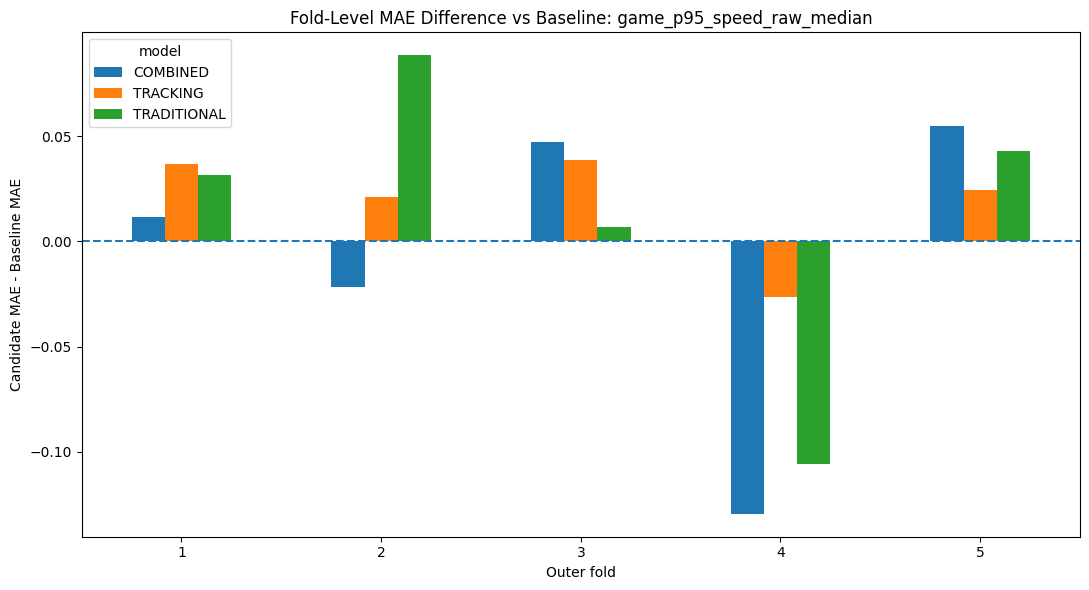

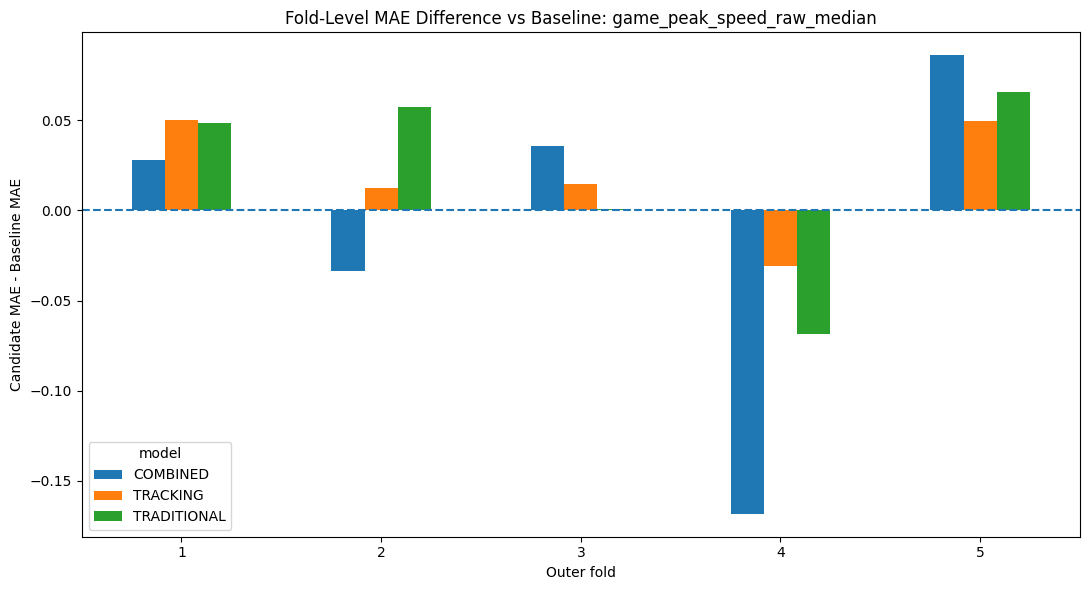

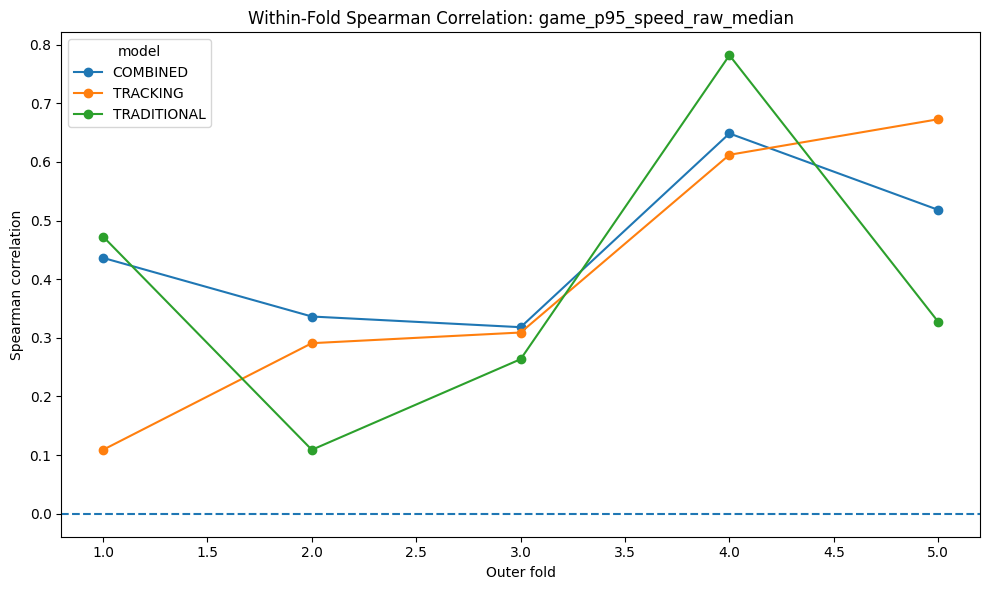

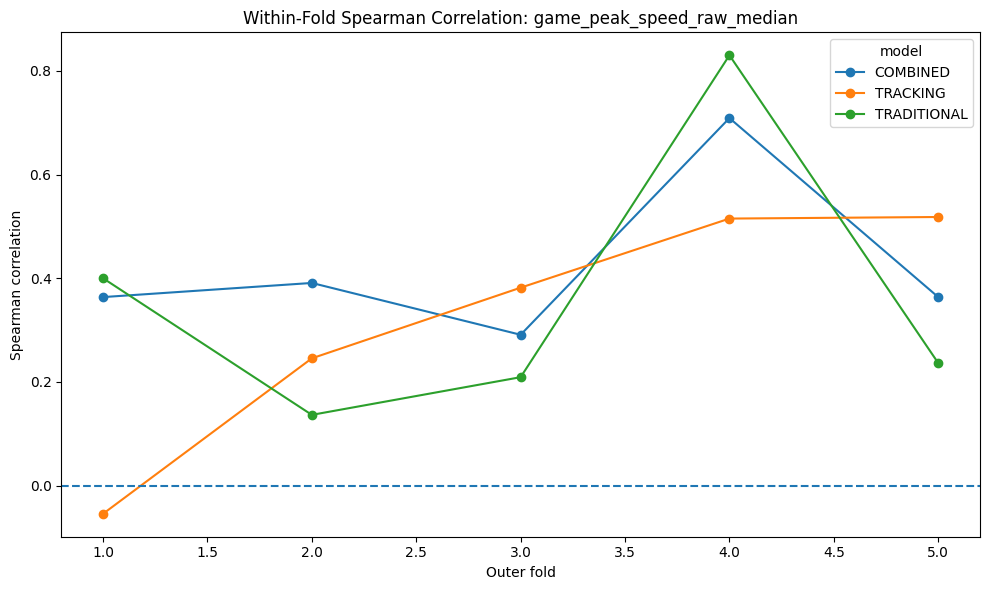

In [14]:
for outcome in PRIMARY_OUTCOMES:

    plot_data = fold_differences[
        fold_differences.outcome == outcome
    ]

    pivot = plot_data.pivot(
        index="outer_fold",
        columns="model",
        values="mae_difference"
    )

    ax = pivot.plot(
        kind="bar",
        figsize=(11, 6)
    )

    ax.axhline(0, linestyle="--")

    ax.set_title(
        f"Fold-Level MAE Difference vs Baseline: {outcome}"
    )

    ax.set_xlabel("Outer fold")
    ax.set_ylabel("Candidate MAE - Baseline MAE")

    plt.xticks(rotation=0)
    plt.tight_layout()

    plt.savefig(
        OUT_DIR / f"{outcome}_fold_mae_comparison.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()


for outcome in PRIMARY_OUTCOMES:

    plot_data = fold_metrics[
        (fold_metrics.outcome == outcome)
        & (fold_metrics.model != "BASELINE")
    ]

    pivot = plot_data.pivot(
        index="outer_fold",
        columns="model",
        values="spearman_rho"
    )

    ax = pivot.plot(
        marker="o",
        figsize=(10, 6)
    )

    ax.axhline(0, linestyle="--")

    ax.set_title(
        f"Within-Fold Spearman Correlation: {outcome}"
    )

    ax.set_xlabel("Outer fold")
    ax.set_ylabel("Spearman correlation")

    plt.xticks(rotation=0)
    plt.tight_layout()

    plt.savefig(
        OUT_DIR / f"{outcome}_within_fold_spearman.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

In [15]:
print("=" * 85)
print("NOTEBOOK 08D — RESEARCH INTERPRETATION")
print("=" * 85)

for outcome in PRIMARY_OUTCOMES:

    print("\nOUTCOME:", outcome)

    subset = primary_decisions[
        primary_decisions.outcome == outcome
    ]

    for _, row in subset.iterrows():

        print("\nMODEL:", row.model)

        print(
            "Equal-fold MAE difference:",
            round(row.point_estimate, 5)
        )

        print(
            "95% CI:",
            round(row.ci_2_5, 5),
            "to",
            round(row.ci_97_5, 5)
        )

        print(
            "Folds improved:",
            row.folds_model_better,
            "/ 5"
        )

        print(
            "Decision:",
            row.interpretation
        )

print("\nInterpretation cautions:")
print("- Five folds contain only 10–11 receivers each.")
print("- Bootstrap intervals condition on the existing fold design.")
print("- Correlation does not establish accurate calibration.")
print("- Multiple outcome/model comparisons require caution.")
print("- No causal or external-generalisation claim is justified.")

NOTEBOOK 08D — RESEARCH INTERPRETATION

OUTCOME: game_p95_speed_raw_median

MODEL: TRADITIONAL
Equal-fold MAE difference: 0.01262
95% CI: -0.03464 to 0.06045
Folds improved: 1 / 5
Decision: UNCERTAIN_CI_INCLUDES_ZERO

MODEL: TRACKING
Equal-fold MAE difference: 0.01887
95% CI: -0.01502 to 0.05504
Folds improved: 1 / 5
Decision: UNCERTAIN_CI_INCLUDES_ZERO

MODEL: COMBINED
Equal-fold MAE difference: -0.00755
95% CI: -0.06778 to 0.05437
Folds improved: 2 / 5
Decision: UNCERTAIN_CI_INCLUDES_ZERO

OUTCOME: game_peak_speed_raw_median

MODEL: TRADITIONAL
Equal-fold MAE difference: 0.02083
95% CI: -0.02498 to 0.06765
Folds improved: 1 / 5
Decision: UNCERTAIN_CI_INCLUDES_ZERO

MODEL: TRACKING
Equal-fold MAE difference: 0.01922
95% CI: -0.01666 to 0.05553
Folds improved: 1 / 5
Decision: UNCERTAIN_CI_INCLUDES_ZERO

MODEL: COMBINED
Equal-fold MAE difference: -0.01033
95% CI: -0.0774 to 0.05518
Folds improved: 2 / 5
Decision: UNCERTAIN_CI_INCLUDES_ZERO

Interpretation cautions:
- Five folds contain 

In [16]:
def sha256(path):
    h = hashlib.sha256()

    with open(path, "rb") as f:
        for chunk in iter(
            lambda: f.read(1024 * 1024),
            b""
        ):
            h.update(chunk)

    return h.hexdigest()


manifest = {
    "notebook": "08D_fold_stratified_receiver_validation.ipynb",
    "seed": SEED,
    "bootstrap_replicates": N_BOOT,
    "oof_rows": int(len(oof)),
    "receivers": int(oof.nfl_id.nunique()),
    "outer_folds": sorted(map(int, folds.outer_fold.unique())),
    "outcomes": sorted(oof.outcome.unique().tolist()),
    "models": sorted(oof.model.unique().tolist()),
    "models_refit": False,
    "fold_assignment_validation": "PASS",
    "primary_estimand": (
        "Equal-weight mean of five fold-specific "
        "receiver-level paired MAE differences."
    ),
    "bootstrap_method": (
        "Receiver resampling within original outer folds."
    ),
    "core_dataset_sha256": sha256(DATASET_PATH),
    "oof_sha256": sha256(OOF_PATH),
    "fold_assignments_sha256": sha256(FOLD_PATH)
}

with open(
    OUT_DIR / "fold_stratified_receiver_validation_manifest.json",
    "w",
    encoding="utf-8"
) as f:
    json.dump(manifest, f, indent=4)

expected_outputs = [
    "receiver_level_within_fold_predictions.csv",
    "fold_stratified_receiver_metrics.csv",
    "within_fold_correlation_summary.csv",
    "paired_receiver_mae_differences_by_fold.csv",
    "equal_fold_mae_difference_summary.csv",
    "fold_stratified_receiver_bootstrap.csv",
    "receiver_weighted_mae_sensitivity.csv",
    "primary_speed_outcome_decisions.csv",
    "combined_model_fold_stability.csv",
    "fold_stratified_receiver_validation_manifest.json"
]

missing = [
    name for name in expected_outputs
    if not (OUT_DIR / name).exists()
]

assert not missing, f"Missing outputs: {missing}"

print("=" * 80)
print("NOTEBOOK 08D COMPLETE")
print("=" * 80)
print("OOF rows:", len(oof))
print("Receivers:", oof.nfl_id.nunique())
print("Folds:", folds.outer_fold.nunique())
print("Bootstrap:", N_BOOT)
print("Missing outputs:", missing)
print("Output:", OUT_DIR)

NOTEBOOK 08D COMPLETE
OOF rows: 2232
Receivers: 54
Folds: 5
Bootstrap: 5000
Missing outputs: []
Output: D:\PROJECTS\WR-MovementIQ\reports\fold_stratified_receiver_validation
